# Comparing Jacobi and Gauss-Seidel iteration

Both methods solve the same system. The convergence plot uses the residual after each complete iteration.

Jacobi: [ 0.18611987  0.33123028 -0.42271293]
Gauss-Seidel: [ 0.18611987  0.33123028 -0.42271293]


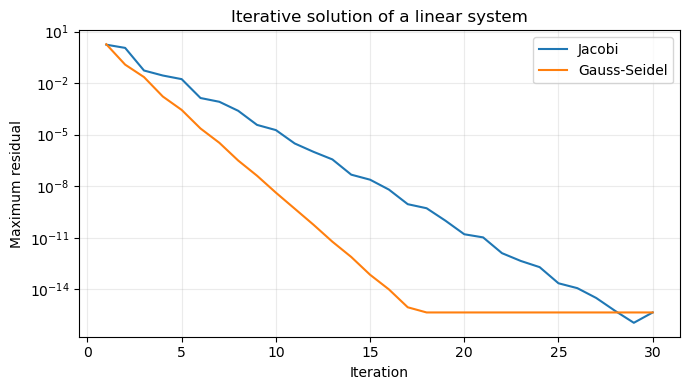

In [1]:
import numpy as np
import matplotlib.pyplot as plt

A = np.array([[5, -2, 3], [-3, 9, 1], [-2, 1, 7]], dtype=float)
b = np.array([-1, 2, -3], dtype=float)

def iterate(method, count=30):
    x = np.zeros(3)
    residuals = []
    for _ in range(count):
        old = x.copy()
        for i in range(len(x)):
            values = old if method == 'Jacobi' else x
            other = A[i] @ values - A[i, i] * values[i]
            x[i] = (b[i] - other) / A[i, i]
        residuals.append(np.linalg.norm(A @ x - b, ord=np.inf))
    return x, residuals

fig, ax = plt.subplots(figsize=(7, 4))
for method in ['Jacobi', 'Gauss-Seidel']:
    x, residuals = iterate(method)
    ax.semilogy(np.arange(1, 31), residuals, label=method)
    print(f"{method}: {x}")
    assert np.allclose(A @ x, b, atol=1e-5)
ax.set(xlabel='Iteration', ylabel='Maximum residual', title='Iterative solution of a linear system')
ax.grid(alpha=.25)
ax.legend()
plt.tight_layout()
plt.show()